# Multilabel classification with CCA and PCA

This notebook replays `examples/miscellaneous/plot_multilabel.py` from
scikit-learn revision `4358542a1bd39af2e7e1cbace8b9fed067473c5b`. The
reference example is by the scikit-learn developers and is distributed under
the [BSD 3-Clause License](../../LICENSES/scikit-learn.txt).

The example generates two document datasets with `random_state=1`. One
allows documents with neither label. CCA uses the two indicator columns to
learn its projection, while PCA uses only the document features. A linear
SVC per label learns a boundary on each two-dimensional projection.

Both implementations fit and predict on the same samples, as in the
gallery example. The plots illustrate the fitted boundaries.

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path
from unittest.mock import patch

import matplotlib.pyplot as plt
import numpy as np
import sklearn

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("cross_decomposition/plot_multilabel")

reference = ROOT.parent / "scikit-learn"
revision = "4358542a1bd39af2e7e1cbace8b9fed067473c5b"
reference_files = [
    "examples/miscellaneous/plot_multilabel.py",
    "sklearn/datasets/_samples_generator.py",
    "sklearn/cross_decomposition/_pls.py",
    "sklearn/decomposition/_base.py",
    "sklearn/decomposition/_pca.py",
    "sklearn/utils/_array_api.py",
    "sklearn/multiclass.py",
    "sklearn/svm/_base.py",
    "sklearn/svm/_classes.py",
]
assert subprocess.check_output(
    ["git", "-C", reference, "rev-parse", "HEAD"], text=True
).strip() == revision
assert not subprocess.check_output(
    ["git", "-C", reference, "status", "--porcelain", "--", *reference_files], text=True
)
assert sklearn.__version__ == "1.9.1"

# Execute the pinned Python estimator sources. The locked wheel supplies
# supporting utilities and compiled extensions, including libsvm.
def load_reference(path):
    name = path.removesuffix(".py").replace("/", ".")
    package, _, module = name.rpartition(".")
    spec = importlib.util.spec_from_file_location(
        f"{package}._moxie_reference{module}", reference / path
    )
    source = importlib.util.module_from_spec(spec)
    previous = sys.dont_write_bytecode
    try:
        sys.dont_write_bytecode = True
        spec.loader.exec_module(source)
    finally:
        sys.dont_write_bytecode = previous
    return source


make_multilabel_classification = load_reference(
    "sklearn/datasets/_samples_generator.py"
).make_multilabel_classification
CCA = load_reference("sklearn/cross_decomposition/_pls.py").CCA
pinned_array_api = load_reference("sklearn/utils/_array_api.py")
with patch.dict(sys.modules, {"sklearn.utils._array_api": pinned_array_api}):
    pinned_pca_base = load_reference("sklearn/decomposition/_base.py")
    with patch.dict(sys.modules, {"sklearn.decomposition._base": pinned_pca_base}):
        PCA = load_reference("sklearn/decomposition/_pca.py").PCA
OneVsRestClassifier = load_reference("sklearn/multiclass.py").OneVsRestClassifier
import sklearn.svm

with patch.dict(sys.modules, {"sklearn.svm._base": load_reference("sklearn/svm/_base.py")}):
    SVC = load_reference("sklearn/svm/_classes.py").SVC

## scikit-learn reference

In [2]:
datasets = {
    name: make_multilabel_classification(
        n_classes=2, n_labels=1, allow_unlabeled=allow, random_state=1
    )
    for name, allow in (("with_unlabeled", True), ("without_unlabeled", False))
}
expected = {}
for name, (X, Y) in datasets.items():
    nb.share(**{
        f"{name}_X": X.astype(np.float64),
        f"{name}_Y": Y.astype(np.int64),
    })
    projections = {
        "cca": CCA(n_components=2).fit(X, Y).transform(X),
        "pca": PCA(n_components=2).fit_transform(X),
    }
    for algorithm, projected in projections.items():
        key = f"{name}_{algorithm}"
        fitted = OneVsRestClassifier(SVC(kernel="linear")).fit(projected, Y)
        expected[f"{key}_projected"] = projected
        expected[f"{key}_classes"] = fitted.classes_
        expected[f"{key}_prediction"] = fitted.predict(projected)
        expected[f"{key}_decision"] = fitted.decision_function(projected)
        for label, estimator in enumerate(fitted.estimators_):
            expected[f"{key}_coef_{label}"] = estimator.coef_
            expected[f"{key}_intercept_{label}"] = estimator.intercept_

## Moxie in native Mojo

CCA takes a Float64 target matrix. OvR takes the same values as an Int64
indicator matrix, and `BinaryAdapter` converts each indicator column to the
list of numeric labels accepted by SVC. Access each fitted SVC through
`estimators_[label].estimator().estimator` and read its linear coefficients with
`coef_()`.

In [3]:
%%mojo multilabel
from moxie.cross_decomposition import CCA
from moxie.decomposition import PCA
from moxie.multiclass import BinaryAdapter, OneVsRestClassifier
from moxie.svm import SVC
from moxie_nb_io import load, save
from numojo import NDArray


def classify(
    key: String, projected: NDArray[DType.float64], labels: NDArray[DType.int64],
) raises:
    var fitted = OneVsRestClassifier(BinaryAdapter(SVC(kernel="linear")))
    _ = fitted.fit(projected, labels)
    save(key + "_projected", projected)
    save(key + "_classes", fitted.classes_)
    save(key + "_prediction", fitted.predict(projected))
    save(key + "_decision", fitted.decision_function(projected))
    for label in range(len(fitted.estimators_)):
        ref svc = fitted.estimators_[label].estimator().estimator
        save(key + "_coef_" + String(label), svc.coef_())
        save(key + "_intercept_" + String(label), svc.intercept_)


def run(name: String) raises:
    var X = load(name + "_X")
    var labels = load[DType.int64](name + "_Y")
    var cca = CCA(n_components=2)
    _ = cca.fit(X, labels.astype[DType.float64]())
    classify(name + "_cca", cca.transform(X), labels)
    var pca = PCA(n_components=2)
    classify(name + "_pca", pca.fit_transform(X), labels)


def main() raises:
    run("with_unlabeled")
    run("without_unlabeled")

## Side-by-side projections and boundaries

Circles show the observed labels. Dashed and dotted lines show the fitted
zero-decision contours for the two labels.

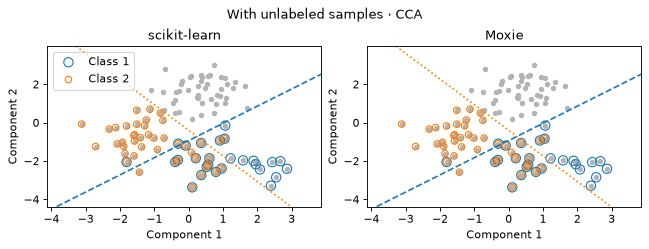

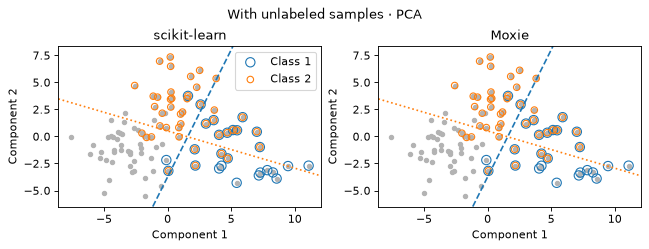

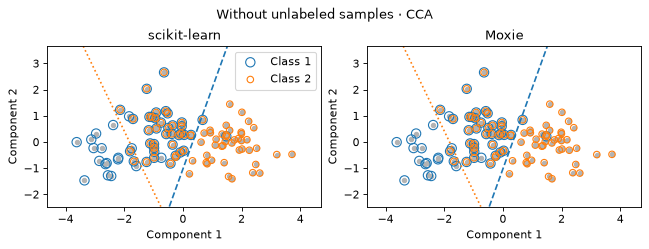

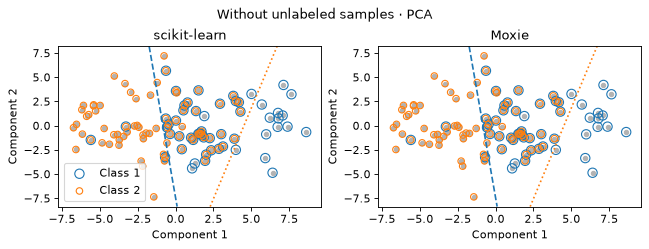

In [4]:
actual = nb.results["multilabel"]

def plot_comparison(dataset, algorithm, label):
    _, Y = datasets[dataset]
    key = f"{dataset}_{algorithm}"
    fig, axes = plt.subplots(1, 2, figsize=(8, 3), layout="constrained")
    fig.suptitle(f"{label} · {algorithm.upper()}")
    for ax, (name, result) in zip(axes, (("scikit-learn", expected), ("Moxie", actual))):
        x, y = result[f"{key}_projected"].T
        ax.scatter(x, y, c="0.7", s=15)
        for k, (color, style) in enumerate((("tab:blue", "--"), ("tab:orange", ":"))):
            rows = Y[:, k].astype(bool)
            ax.scatter(x[rows], y[rows], facecolors="none", edgecolors=color,
                       s=(70, 34)[k], label=f"Class {k + 1}")
            weights = result[f"{key}_coef_{k}"][0]
            bias = result[f"{key}_intercept_{k}"][0]
            # Draw the line through the closest point to the origin. This
            # also handles a vertical boundary without dividing by a component.
            point = -bias * weights / (weights @ weights)
            ax.axline(point, point + [-weights[1], weights[0]], color=color, linestyle=style)
        ax.set(title=name, xlabel="Component 1", ylabel="Component 2",
               xlim=(x.min() - 1, x.max() + 1), ylim=(y.min() - 1, y.max() + 1))
    axes[0].legend(loc="best")
    plt.show()


plt.rcParams["figure.dpi"] = 80
for dataset, label in (("with_unlabeled", "With unlabeled samples"),
                       ("without_unlabeled", "Without unlabeled samples")):
    for algorithm in ("cca", "pca"):
        plot_comparison(dataset, algorithm, label)

## Parity

Projection shape, dtype and signed coordinates are checked directly, without
sign alignment. The Float64 coordinate tolerance allows for different
decomposition backends and reduction order. OvR class order and predicted
label indicators must match exactly. Decision values, coefficients and
intercepts are checked separately to detect shifts in the fitted boundaries.

For CCA without unlabeled documents, Float64 roundoff in the projection
moves one class 1 dual coefficient onto its upper bound. This leaves no free
support vector for that class. LIBSVM then uses the midpoint of the admissible
intercept interval. The resulting intercept and decision shift is about
0.00374 with unchanged coefficients and label indicators. The end-to-end
tolerance for that offset is 0.004. A second check fits the reference SVC on
the exact Mojo coordinates to isolate the solver from projection roundoff.

In [5]:
tight = dict(rtol=1e-9, atol=1e-10,
             reason="Float64 projection and SVC evaluation roundoff")
offset_tolerance = dict(rtol=0, atol=4e-3,
                        reason="Class 1 has a 0.00374 intercept shift at the dual bound")
sensitive = "without_unlabeled_cca"

for key, ref in expected.items():
    native = actual[key]
    nb.compare(key + " dtype", str(ref.dtype), str(native.dtype), exact=True)
    if key.endswith(("_classes", "_prediction")):
        nb.compare(key, ref, native, exact=True)
    elif key == f"{sensitive}_decision":
        nb.compare(key + " class 1", ref[:, 0], native[:, 0], **offset_tolerance)
        nb.compare(key + " class 2", ref[:, 1], native[:, 1], **tight)
    elif key == f"{sensitive}_intercept_0":
        nb.compare(key, ref, native, **offset_tolerance)
    else:
        nb.compare(key, ref, native, **tight)

_, Y = datasets["without_unlabeled"]
projected = actual[f"{sensitive}_projected"]
same_input = OneVsRestClassifier(SVC(kernel="linear")).fit(projected, Y)
nb.compare("Decision values on identical CCA coordinates",
           same_input.decision_function(projected), actual[f"{sensitive}_decision"], **tight)
nb.compare("Class 1 intercept on identical CCA coordinates",
           same_input.estimators_[0].intercept_, actual[f"{sensitive}_intercept_0"], **tight)

nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
with_unlabeled_cca_projected dtype,PASS,(),(),,,exact,0 mismatches,
with_unlabeled_cca_projected,PASS,"(100, 2)","(100, 2)",4.45e-12,7.32e-11,"rtol=1e-09, atol=1e-10",,Float64 projection and SVC evaluation roundoff
with_unlabeled_cca_classes dtype,PASS,(),(),,,exact,0 mismatches,
with_unlabeled_cca_classes,PASS,"(2,)","(2,)",,,exact,0 mismatches,
with_unlabeled_cca_prediction dtype,PASS,(),(),,,exact,0 mismatches,
with_unlabeled_cca_prediction,PASS,"(100, 2)","(100, 2)",,,exact,0 mismatches,
with_unlabeled_cca_decision dtype,PASS,(),(),,,exact,0 mismatches,
with_unlabeled_cca_decision,PASS,"(100, 2)","(100, 2)",6.6e-12,9.42e-12,"rtol=1e-09, atol=1e-10",,Float64 projection and SVC evaluation roundoff
with_unlabeled_cca_coef_0 dtype,PASS,(),(),,,exact,0 mismatches,
with_unlabeled_cca_coef_0,PASS,"(1, 2)","(1, 2)",1.95e-12,1.5e-12,"rtol=1e-09, atol=1e-10",,Float64 projection and SVC evaluation roundoff
